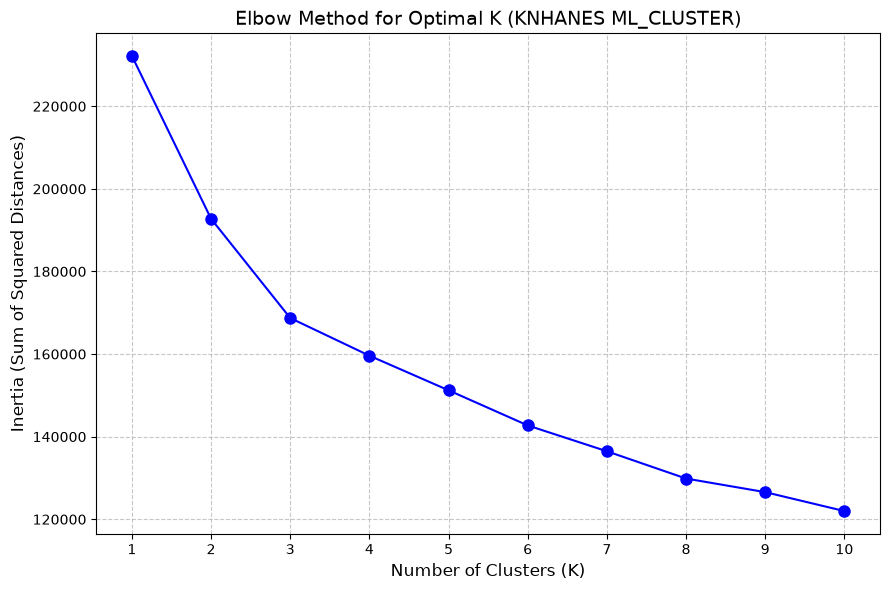

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. 데이터 불러오기 및 전처리
ml_data = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]
X = ml_data[features].copy()

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 2. 엘보우 기법(Elbow Method)을 위한 Inertia 계산
# 그룹(K)을 1개부터 10개까지 늘려가며 뭉침새(Inertia)를 측정합니다.
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    # kmeans.inertia_ 는 그룹 내 데이터들이 얼마나 조밀하게 뭉쳐있는지를 나타내는 수치입니다. (작을수록 좋음)
    inertias.append(kmeans.inertia_)

# 3. 그래프 그리기
plt.figure(figsize=(9, 6))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='b', markersize=8)
plt.title('Elbow Method for Optimal K (KNHANES ML_CLUSTER)', fontsize=14)
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('elbow_method.png')
plt.show()

데이터 준비 중...
각 K별 실루엣 점수를 계산 중입니다. (1~2분 정도 소요될 수 있습니다)
K=2일 때 실루엣 점수: 0.1733
K=3일 때 실루엣 점수: 0.1817
K=4일 때 실루엣 점수: 0.1812
K=5일 때 실루엣 점수: 0.1419
K=6일 때 실루엣 점수: 0.1609
K=7일 때 실루엣 점수: 0.1498
K=8일 때 실루엣 점수: 0.1514
K=9일 때 실루엣 점수: 0.1361
K=10일 때 실루엣 점수: 0.1399

그래프 창이 팝업됩니다.


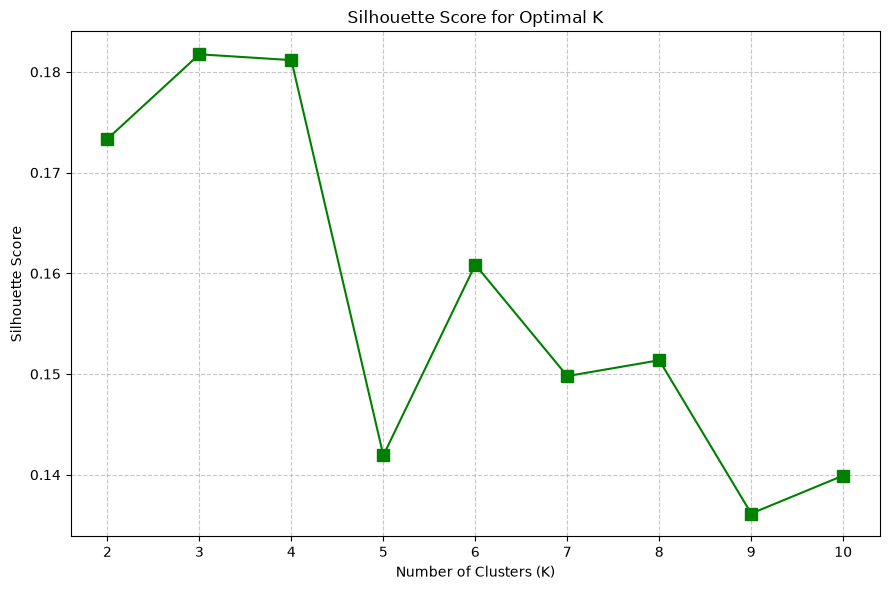

In [2]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. 데이터 불러오기 및 전처리
print("데이터 준비 중...")
ml_data = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]
X = ml_data[features].copy()

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 2. 2개부터 10개까지 실루엣 점수 계산
print("각 K별 실루엣 점수를 계산 중입니다. (1~2분 정도 소요될 수 있습니다)")
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    # 실루엣 점수 계산 함수 적용
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)
    print(f"K={k}일 때 실루엣 점수: {score:.4f}")

# 3. 결과 그래프 그리기
plt.figure(figsize=(9, 6))
plt.plot(K_range, silhouette_scores, marker='s', linestyle='-', color='g', markersize=8)
plt.title('Silhouette Score for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

print("\n그래프 창이 팝업됩니다.")
plt.show()

데이터를 준비하고 세 가지 지표를 계산합니다. (약 1~2분 소요)
K=2 계산 완료
K=3 계산 완료
K=4 계산 완료
K=5 계산 완료
K=6 계산 완료
K=7 계산 완료
K=8 계산 완료
K=9 계산 완료
K=10 계산 완료


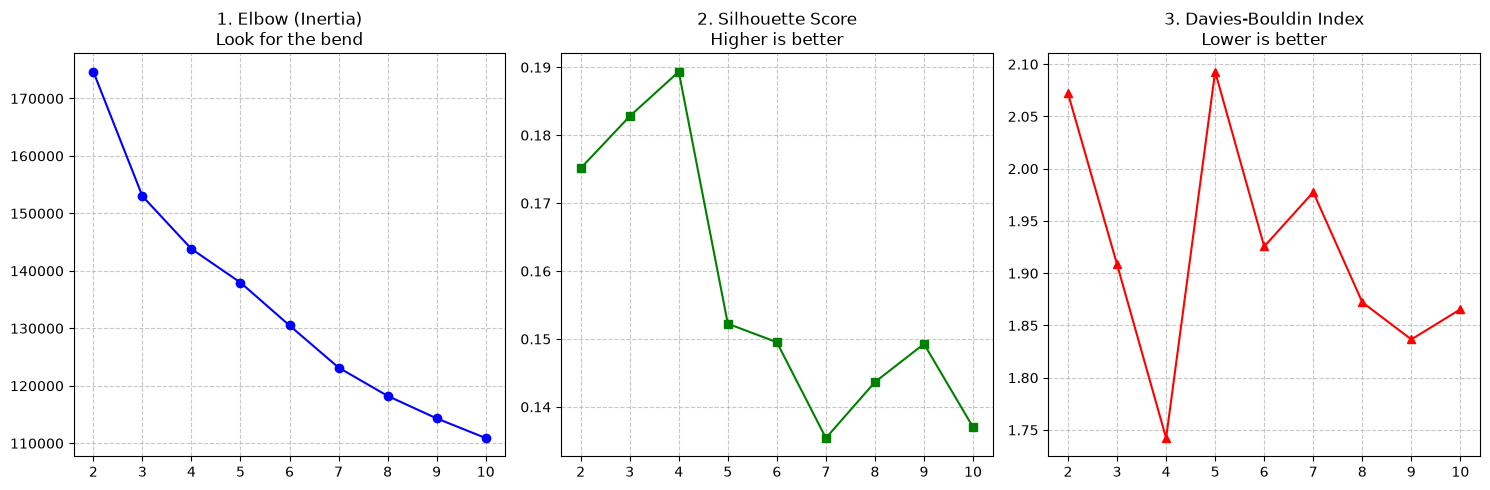

In [5]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt

print("데이터를 준비하고 세 가지 지표를 계산합니다. (약 1~2분 소요)")
# 1. 데이터 준비
ml_data = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER_COMPLETECASE.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]
X = ml_data[features].copy()

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# 2. 세 가지 지표 계산 (K=2 부터 10까지)
K_range = range(2, 11)
inertias, silhouettes, db_scores = [], [], []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    print(f"K={k} 계산 완료")

# 3. 그래프 3개 나란히 그리기
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# (1) Elbow (Inertia) - 꺾이는 부분 찾기
axes[0].plot(K_range, inertias, marker='o', color='blue')
axes[0].set_title('1. Elbow (Inertia)\nLook for the bend')
axes[0].grid(True, linestyle='--', alpha=0.7)

# (2) Silhouette - 높을수록 좋음
axes[1].plot(K_range, silhouettes, marker='s', color='green')
axes[1].set_title('2. Silhouette Score\nHigher is better')
axes[1].grid(True, linestyle='--', alpha=0.7)

# (3) Davies-Bouldin - 낮을수록 좋음
axes[2].plot(K_range, db_scores, marker='^', color='red')
axes[2].set_title('3. Davies-Bouldin Index\nLower is better')
axes[2].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

각 알고리즘의 최적 구조를 찾는 3가지 그래프를 그립니다. (약 1분 소요)


C:\Users\최지연\AppData\Local\Temp\ipykernel_27424\3476090919.py:52: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\최지연\AppData\Local\Temp\ipykernel_27424\3476090919.py:52: UserWarning: Glyph 47353 (\N{HANGUL SYLLABLE RUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\최지연\AppData\Local\Temp\ipykernel_27424\3476090919.py:52: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\최지연\AppData\Local\Temp\ipykernel_27424\3476090919.py:52: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\최지연\AppData\Local\Temp\ipykernel_27424\3476090919.py:52: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\최지연\AppData\Local\Temp\ipykernel_27424\3476090919.py:52: UserWarning: Glyph 45230 (\N{HANGUL SYLLABLE NAJ}) missing from font(s) Dej

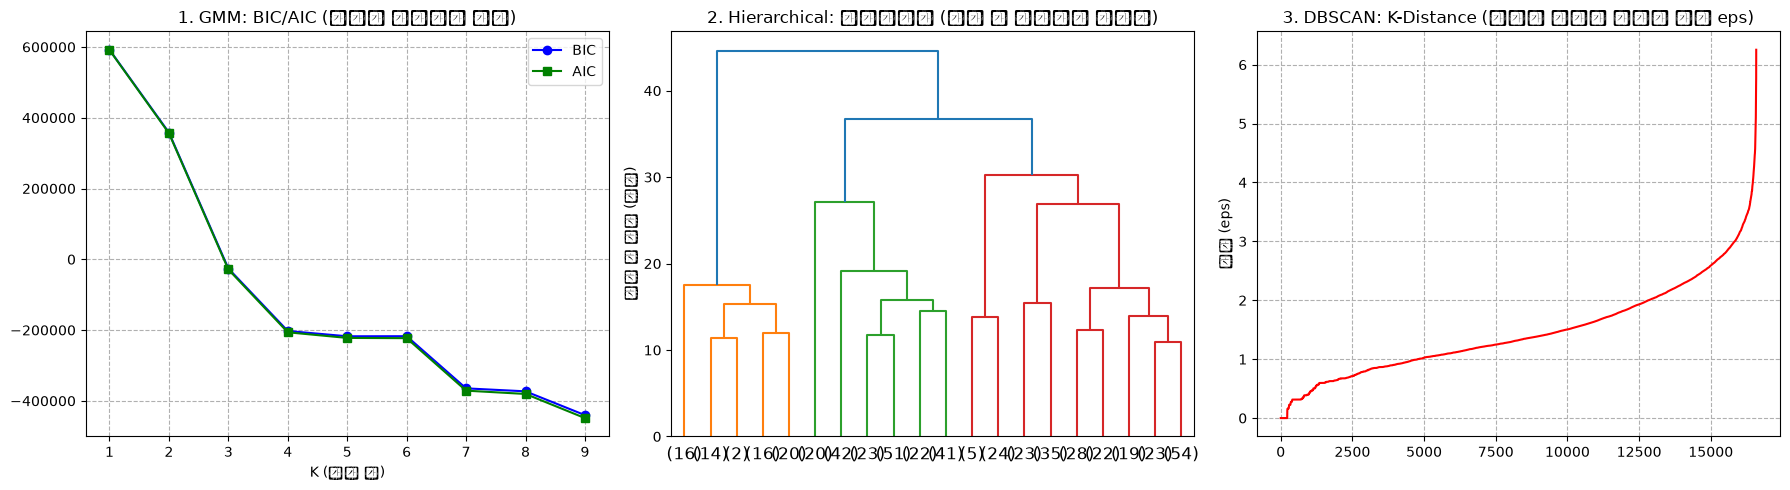

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

print("각 알고리즘의 최적 구조를 찾는 3가지 그래프를 그립니다. (약 1분 소요)")
# 데이터 준비
ml_data = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]
X = ml_data[features].copy()
imputer = SimpleImputer(strategy='median')
X_scaled = StandardScaler().fit_transform(imputer.fit_transform(X))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. GMM: BIC/AIC 점수
K_range = range(1, 10)
bic, aic = [], []
for k in K_range:
    gmm = GaussianMixture(n_components=k, random_state=42)
    gmm.fit(X_scaled)
    bic.append(gmm.bic(X_scaled))
    aic.append(gmm.aic(X_scaled))

axes[0].plot(K_range, bic, marker='o', label='BIC', color='blue')
axes[0].plot(K_range, aic, marker='s', label='AIC', color='green')
axes[0].set_title('1. GMM: BIC/AIC (점수가 낮을수록 최적)')
axes[0].set_xlabel('K (그룹 수)')
axes[0].legend()
axes[0].grid(True, linestyle='--')

# 2. 계층적 군집화: 덴드로그램 (빠른 시각화를 위해 500명 샘플링)
np.random.seed(42)
sample_idx = np.random.choice(len(X_scaled), 500, replace=False)
Z = linkage(X_scaled[sample_idx], method='ward')
dendrogram(Z, truncate_mode='lastp', p=20, ax=axes[1])
axes[1].set_title('2. Hierarchical: 덴드로그램 (가장 긴 세로선을 자르기)')
axes[1].set_ylabel('그룹 간 거리 (차이)')

# 3. DBSCAN: K-Distance (최적의 거리 eps 찾기)
neigh = NearestNeighbors(n_neighbors=14)
distances = np.sort(neigh.fit(X_scaled).kneighbors(X_scaled)[0][:, 13], axis=0)
axes[2].plot(distances, color='red')
axes[2].set_title('3. DBSCAN: K-Distance (급격히 꺾이는 지점이 최적 eps)')
axes[2].set_ylabel('거리 (eps)')
axes[2].grid(True, linestyle='--')

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
import numpy as np
import time
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist

# K-Medoids 자체 구현 함수 (추가 설치 불필요)
def kmedoids_fast(X, k, max_iter=100, random_state=42):
    np.random.seed(random_state)
    # 초기 중심점을 실제 데이터 중에서 무작위 선택
    medoid_indices = np.random.choice(len(X), k, replace=False)
    medoids = X[medoid_indices]
    
    for _ in range(max_iter):
        # 모든 데이터와 중심점 간의 거리 계산 및 군집 할당
        distances = cdist(X, medoids, metric='euclidean')
        labels = np.argmin(distances, axis=1)
        
        new_medoid_indices = np.zeros(k, dtype=int)
        for i in range(k):
            cluster_idx = np.where(labels == i)[0]
            if len(cluster_idx) == 0:
                new_medoid_indices[i] = medoid_indices[i]
                continue
            
            # 군집 내 모든 포인트 간의 거리를 계산하여 합이 최소인 '실제 데이터'를 새 중심으로 지정
            cluster_points = X[cluster_idx]
            intra_dist = cdist(cluster_points, cluster_points, metric='euclidean')
            best_idx = np.argmin(intra_dist.sum(axis=1))
            new_medoid_indices[i] = cluster_idx[best_idx]
            
        # 중심점이 더 이상 변하지 않으면 종료
        if np.array_equal(medoid_indices, new_medoid_indices):
            break
        medoid_indices = new_medoid_indices
        medoids = X[medoid_indices]
        
    return labels

# 1. 데이터 로드 및 스케일링
df = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER_COMPLETECASE.csv')
features = [col for col in df.columns if col.startswith('ML_')]
X = df[features].values
X_scaled = StandardScaler().fit_transform(X)

# 2. K-Means (k=4) 학습 및 평가
start_time = time.time()
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_time = time.time() - start_time
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)

# 3. 자체 구현 K-Medoids (k=4) 학습 및 평가
start_time = time.time()
kmedoids_labels = kmedoids_fast(X_scaled, k=4)
kmedoids_time = time.time() - start_time
kmedoids_sil = silhouette_score(X_scaled, kmedoids_labels)

# 4. 결과 비교 출력
print("=== K-Means vs K-Medoids (k=4) 비교 ===")
print(f"[K-Means]  소요시간: {kmeans_time:.2f}초 | 실루엣 점수: {kmeans_sil:.4f}")
print(f"[K-Medoids] 소요시간: {kmedoids_time:.2f}초 | 실루엣 점수: {kmedoids_sil:.4f}")

# 군집 크기 밸런스 확인
df['KMeans_Label'] = kmeans_labels
df['KMedoids_Label'] = kmedoids_labels
print("\n[K-Means 군집 크기]\n", df['KMeans_Label'].value_counts().sort_index())
print("\n[K-Medoids 군집 크기]\n", df['KMedoids_Label'].value_counts().sort_index())

=== K-Means vs K-Medoids (k=4) 비교 ===
[K-Means]  소요시간: 0.24초 | 실루엣 점수: 0.1894
[K-Medoids] 소요시간: 2.05초 | 실루엣 점수: 0.1268

[K-Means 군집 크기]
 KMeans_Label
0     690
1    6463
2    2012
3    5897
Name: count, dtype: int64

[K-Medoids 군집 크기]
 KMedoids_Label
0    5142
1    2344
2    5608
3    1968
Name: count, dtype: int64


In [1]:
import gower, numpy as np, pandas as pd
from sklearn.metrics import silhouette_score

Xg = df[features].copy()
binary_cols = ['ML_smoker', 'ML_drink_month', 'ML_aerobic', 'ML_stress']
cat_mask = Xg.columns.isin(binary_cols)
D = gower.gower_matrix(Xg, cat_features=cat_mask).astype(np.float32)

def run_pam(D, k, n_init=5, max_iter=50, seed=0):
    """미리 계산한 거리행렬 D로 K-Medoids. 초기화를 n_init번 반복해 최선을 선택."""
    n = D.shape[0]
    best_loss, best_lab = np.inf, None
    for s in range(n_init):
        rng = np.random.default_rng(seed + s)
        # k-medoids++ 방식 초기화
        med = [rng.integers(n)]
        for _ in range(k - 1):
            d = D[:, med].min(axis=1).astype(np.float64)
            med.append(rng.choice(n, p=d**2 / (d**2).sum()))
        med = np.array(med)

        for _ in range(max_iter):
            lab = D[:, med].argmin(axis=1)
            new_med = med.copy()
            for c in range(k):
                members = np.where(lab == c)[0]
                if len(members) == 0:
                    continue
                sub = D[np.ix_(members, members)]       # 표본추출 없이 전체 사용
                new_med[c] = members[sub.sum(axis=1).argmin()]
            if np.array_equal(new_med, med):
                break
            med = new_med

NameError: name 'df' is not defined